In [1]:
%matplotlib inline

In [2]:
import scanpy as sc
import os
adata = sc.read_h5ad('Bleomycin_V3V9_RunID-run-240123-105643_ScanpyObject.h5ad')

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
top_n_genes=15
marker_genes_df=pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(top_n_genes)
marker_genes_df

,0,1,2,3,4,5,6,7,8,9
0,Grem1:ENSRNOG00000026053,Hmgb2:ENSRNOG00000013167,Prrg4:ENSRNOG00000022710,Eln:ENSRNOG00000001469,Map1b:ENSRNOG00000017428,Fbn2:ENSRNOG00000043219,Col1a1:ENSRNOG00000003897,Aspm:ENSRNOG00000012318,Dhh:ENSRNOG00000053675,Six3:ENSRNOG00000057031
1,Spp1:ENSRNOG00000043451,LOC100359539:ENSRNOG00000008450,Cdh2:ENSRNOG00000015602,Col1a1:ENSRNOG00000003897,Rock1:ENSRNOG00000031092,Map1b:ENSRNOG00000017428,Acta2:ENSRNOG00000058039,Cenpf:ENSRNOG00000003388,Cldn4:ENSRNOG00000001476,Cck:ENSRNOG00000019321
2,Wif1:ENSRNOG00000004476,Stmn1:ENSRNOG00000016810,Col11a1:ENSRNOG00000023148,Col5a3:ENSRNOG00000020525,Rrbp1:ENSRNOG00000005958,Adra2a:ENSRNOG00000047545,Actn4:ENSRNOG00000020433,Ndc80:ENSRNOG00000013727,Gfpt2:ENSRNOG00000002810,Cpz:ENSRNOG00000008947
3,Ttc27:ENSRNOG00000042932,Top2a:ENSRNOG00000053047,Cdkn1a:ENSRNOG00000000521,Col3a1:ENSRNOG00000003357,S100a6:ENSRNOG00000011647,Igsf3:ENSRNOG00000023851,Cald1:ENSRNOG00000010233,Plk1:ENSRNOG00000018815,Postn:ENSRNOG00000012660,Plcxd2:ENSRNOG00000042289
4,Fibin:ENSRNOG00000004699,Cdk1:ENSRNOG00000000632,Csrp2:ENSRNOG00000003772,Col12a1:ENSRNOG00000058470,Tpr:ENSRNOG00000002394,Zfp36l2:ENSRNOG00000005067,Vcl:ENSRNOG00000010765,Bub1:ENSRNOG00000032778,Tagln:ENSRNOG00000017628,Lipg:ENSRNOG00000018694
5,Ptgs1:ENSRNOG00000007415,Mki67:ENSRNOG00000028137,Igfbp2:ENSRNOG00000016957,Fbn1:ENSRNOG00000007302,Col5a2:ENSRNOG00000003736,Pcdh7:ENSRNOG00000012367,Rock2:ENSRNOG00000004496,Cenpe:ENSRNOG00000009339,RGD1563104:ENSRNOG00000031294,Fam180a:ENSRNOG00000011750
6,Sulf1:ENSRNOG00000009037,Tpx2:ENSRNOG00000008165,Mdm2:ENSRNOG00000006304,Postn:ENSRNOG00000012660,Chd4:ENSRNOG00000018309,Ptprn:ENSRNOG00000019587,Tagln:ENSRNOG00000017628,Knstrn:ENSRNOG00000009334,Nmu:ENSRNOG00000002164,Tekt1:ENSRNOG00000014973
7,Gpx3:ENSRNOG00000052564,Fbxo5:ENSRNOG00000024077,Timp3:ENSRNOG00000004303,Lmod1:ENSRNOG00000051548,Ankrd11:ENSRNOG00000027906,Vgll2:ENSRNOG00000000405,Myh10:ENSRNOG00000002886,Racgap1:ENSRNOG00000049033,Dusp10:ENSRNOG00000004003,Hk3:ENSRNOG00000026235
8,Sfrp4:ENSRNOG00000054957,Kif23:ENSRNOG00000014080,Scx:ENSRNOG00000021812,Actg2:ENSRNOG00000029401,Col8a1:ENSRNOG00000039668,Myh10:ENSRNOG00000002886,Flna:ENSRNOG00000054890,Kif20a:ENSRNOG00000024428,Ppl:ENSRNOG00000002930,Tuba8:ENSRNOG00000048169
9,Itgb5:ENSRNOG00000001795,Cdca8:ENSRNOG00000031431,Gask1b:ENSRNOG00000010183,Serpinf1:ENSRNOG00000003172,Col1a1:ENSRNOG00000003897,Pdgfra:ENSRNOG00000002244,Hip1:ENSRNOG00000001448,Kif20b:ENSRNOG00000018929,Krt8:ENSRNOG00000009779,Gcat:ENSRNOG00000055408


/opt/anaconda3/envs/rnafig/lib/python3.11/site-packages/scanpy/tools/_tsne.py:113: UserWarning: You’re trying to run this on 2000 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


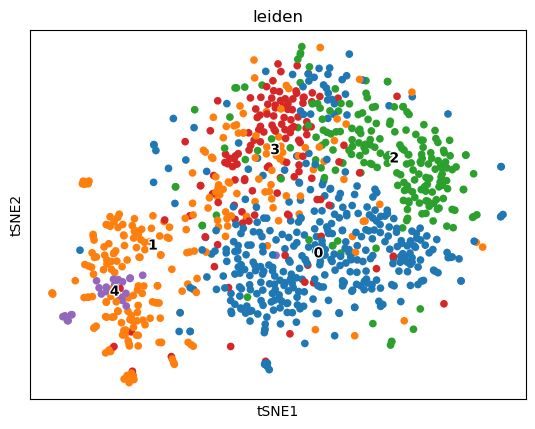

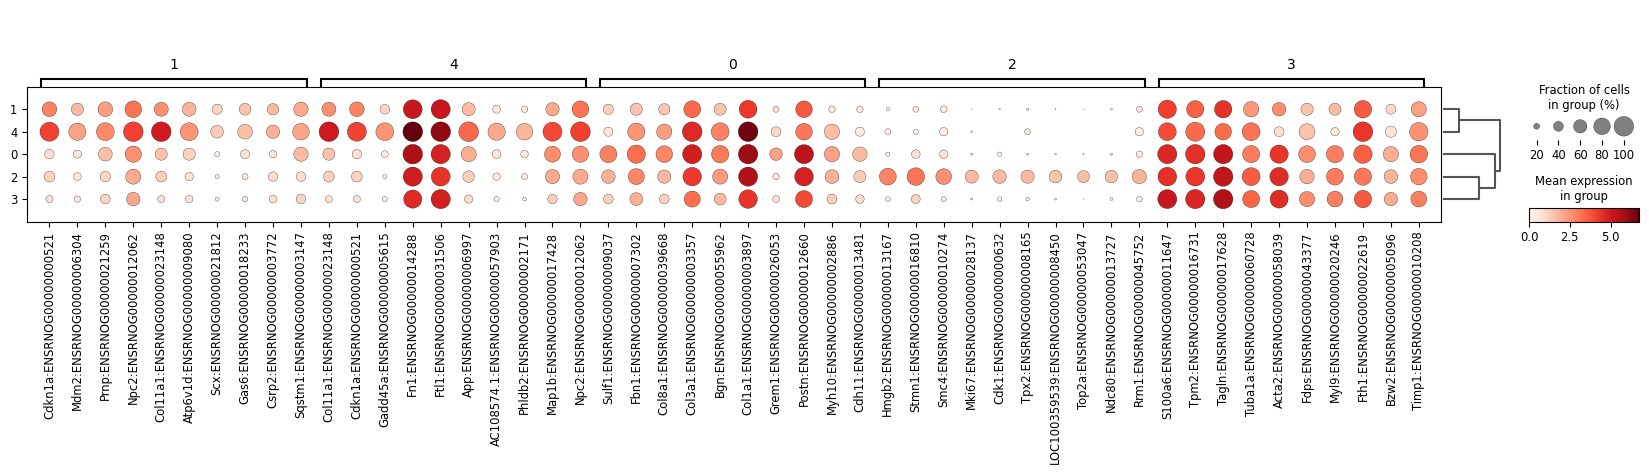

In [13]:
import os
adata = sc.read_h5ad('Bleomycin_V3V9_RunID-run-240123-105643_ScanpyObject.h5ad')
sc.tl.tsne(adata)
sc.tl.leiden(adata, resolution=0.2)#クラスター番号
sc.pl.tsne(adata, color='leiden', legend_loc='on data', legend_fontsize=10, legend_fontoutline=2,return_fig=True)
plt.savefig('Cluster_adata.tiff',bbox_inches='tight')
sc.tl.rank_genes_groups(adata, groupby='leiden', n_genes=adata.shape[1], method='wilcoxon')
sc.pl.rank_genes_groups_dotplot(adata, n_genes=10)

plt.close()

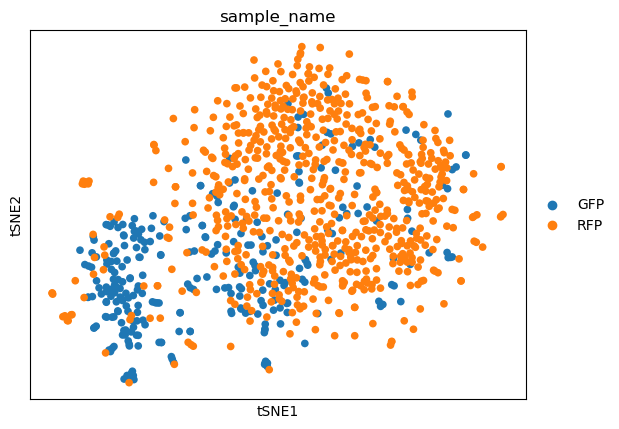

In [5]:
sc.pl.tsne(adata,color="sample_name")

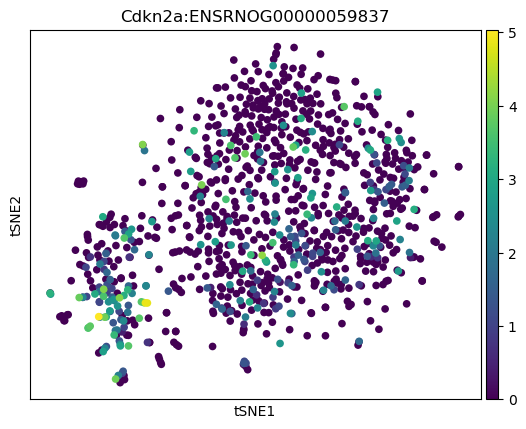

In [6]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
sc.pl.tsne(adata, color='Cdkn2a:ENSRNOG00000059837')


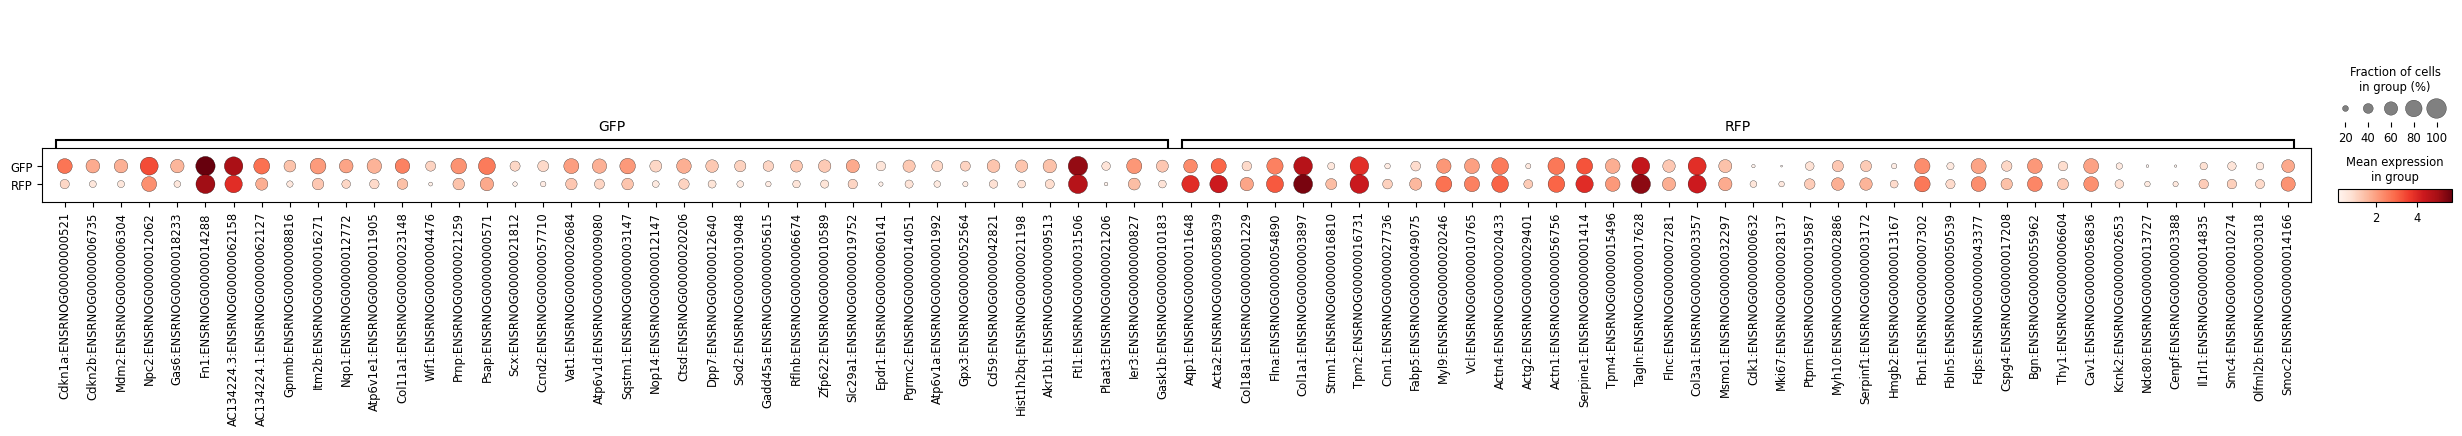

In [6]:
sc.tl.rank_genes_groups(adata, groupby='sample_name', n_genes=adata.shape[1], method='wilcoxon')
sc.pl.rank_genes_groups_dotplot(adata, n_genes=40)


present: 14 missing: ['Il1a', 'Il1b', 'Tnf', 'Ccl8', 'Cxcl2', 'Cxcl5', 'Vegfa', 'Csf2', 'Mmp1', 'Mmp9', 'Mmp14', 'Timp2', 'Icam1', 'Vcam1', 'Sele', 'Vegf1']


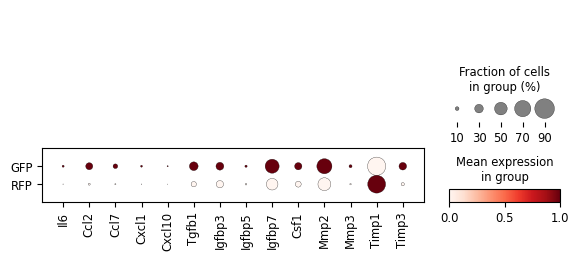

In [24]:
import scanpy as sc
adata.var_names = adata.var["gene_symbol"].astype(str)
adata.var_names_make_unique()

# raw dotplot use_raw=False 
SASP_genes = [
    # Core cytokines / chemokines
    "Il6", "Il1a", "Il1b", "Tnf",
    "Ccl2", "Ccl7", "Ccl8",
    "Cxcl1", "Cxcl2", "Cxcl5", "Cxcl10",

    # Growth factors / signaling
    "Tgfb1", "Igfbp3", "Igfbp5", "Igfbp7",
    "Vegfa", "Csf1", "Csf2",

    # ECM remodeling / fibrosis
    "Mmp1", "Mmp2", "Mmp3", "Mmp9", "Mmp14",
    "Timp1", "Timp2", "Timp3",
    

    # Adhesion / immune interaction
    "Icam1", "Vcam1", "Sele","Vegf1",

]
present = [g for g in SASP_genes if g in adata.var_names]
missing = [g for g in SASP_genes if g not in adata.var_names]
print("present:", len(present), "missing:", missing)

sc.pl.dotplot(
    adata,
    var_names=present,
    groupby="sample_name",
    standard_scale="var",
    use_raw=False
)


In [17]:
from matplotlib import rcParams
rcParams['figure.figsize'] = 3, 6

sc.pl.violin(
    adata,
    keys='Cdkn2a:ENSRNOG00000059837',  # Gene to be visualized
    groupby='sample_name',            # Column name indicating sample groups
    rotation=90,                      # Rotation angle of x-axis labels
    show=False                        # Do not display the plot immediately
)

# Save the plot
plt.savefig('Cdkn2a_violin_plot.tiff', dpi=300, bbox_inches='tight')
plt.close()

In [18]:
from matplotlib import rcParams
rcParams['figure.figsize'] = 3,6
sc.pl.violin(adata, 
             keys='Cdkn1a:ENSRNOG00000000521',  # Gene to be visualized
             groupby='sample_name',   # Column name indicating sample groups
             rotation=90,   # Rotation angle of x-axis labels
             show=False)  # Do not display the plot immediately


plt.savefig('Cdkn1a_violin_plot.tiff', dpi=300, bbox_inches='tight')
plt.close()

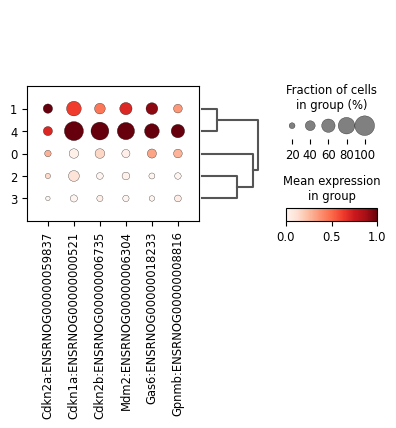

In [14]:
genes_of_interest = [
    "Cdkn2a:ENSRNOG00000059837",
    "Cdkn1a:ENSRNOG00000000521",
    "Cdkn2b:ENSRNOG00000006735",
    "Mdm2:ENSRNOG00000006304",
    "Gas6:ENSRNOG00000018233",
    "Gpnmb:ENSRNOG00000008816",
]

sc.pl.dotplot(
    adata,
    var_names=genes_of_interest,
    groupby="leiden",        # Column in adata.obs indicating cluster identity
    dendrogram=True,         # Display a dendrogram showing similarity between clusters
    standard_scale="var",    # Scale expression values across genes
    show=False               # Do not display the plot immediately
)

# Save the figure
plt.savefig("Cluster_gene6_dif.svg", dpi=300, bbox_inches="tight")
plt.close()

/opt/anaconda3/envs/rnafig/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


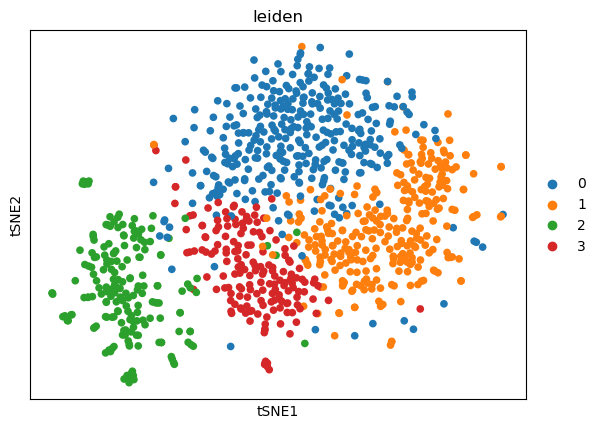

In [7]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=30)
sc.tl.leiden(adata, resolution=0.5)

sc.tl.tsne(adata, use_rep="X_pca")
sc.pl.tsne(adata, color="leiden", save="tsneleiden.svg" )


In [8]:
sc.tl.rank_genes_groups(
    adata,
    groupby="sample_name",
    method="wilcoxon",
)

sc.pl.rank_genes_groups_dotplot(
    adata,
    n_genes=10,
    show=False,
    save="_GFPRFP.svg",   
)

{'mainplot_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

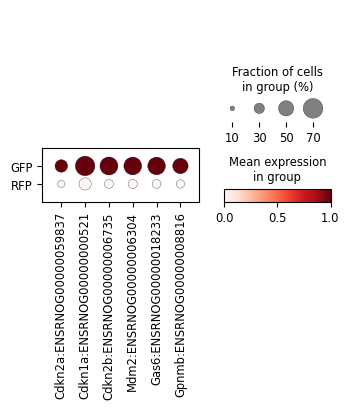

In [16]:
sc.pl.dotplot(
    adata,
    var_names=genes_of_interest,
    groupby="sample_name",   # Column in adata.obs used to group samples
    dendrogram=True,         # Show a dendrogram indicating similarity between groups
    standard_scale="var",    # Scale expression values across genes
    # show=False              # Do not display the plot immediately (optional)
)

# Save the plot
plt.savefig("Cluster_gene6_dif.tiff", dpi=300, bbox_inches="tight")
plt.close()


Number of genes present: 20
Missing genes: ['Il1a', 'Il1b', 'Tnf', 'Ccl8', 'Cxcl2', 'Cxcl5', 'Vegfa', 'Csf2', 'Mmp9', 'Mmp14', 'Timp2', 'Icam1', 'Vcam1', 'Sele', 'Hmgb1']


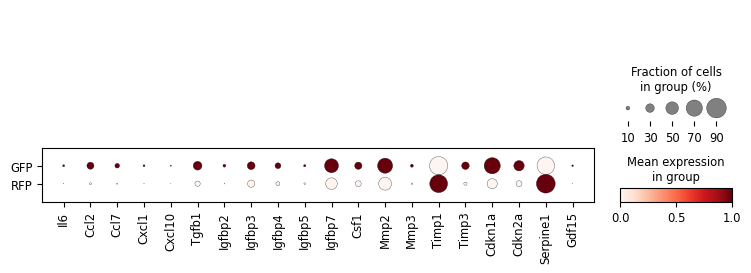

In [9]:
import scanpy as sc
import numpy as np

# --- 0) Set gene symbols as var_names (assuming alias:gene format) ---
# If adata.var.index is in a format like "Il6:ENSRNOG...", this works as intended.
adata.var_names = (
    adata.var.index.to_series()
    .astype(str)
    .str.split(":")
    .str[0]
    .values
)
adata.var_names_make_unique()

# If adata.raw exists, decide whether to use raw or normalized data consistently.
# Here, we assume using normalized adata.X and set use_raw=False.
USE_RAW = False

# --- 1) SASP gene list (can be expanded if needed) ---
SASP_genes = [
    # Core cytokines / chemokines
    "Il6", "Il1a", "Il1b", "Tnf",
    "Ccl2", "Ccl7", "Ccl8",
    "Cxcl1", "Cxcl2", "Cxcl5", "Cxcl10",

    # Growth factors / signaling
    "Tgfb1", "Igfbp2", "Igfbp3", "Igfbp4", "Igfbp5", "Igfbp7",
    "Vegfa", "Csf1", "Csf2",

    # ECM remodeling / protease inhibitors
    "Mmp2", "Mmp3", "Mmp9", "Mmp14",
    "Timp1", "Timp2", "Timp3",

    # Adhesion / immune interaction
    "Icam1", "Vcam1", "Sele",

    # Senescence-associated (supporting markers; optional depending on context)
    "Cdkn1a", "Cdkn2a", "Serpine1", "Gdf15", "Hmgb1",
]

# --- 2) Check which genes are present / missing (case-insensitive rescue) ---
varset = set(adata.var_names)

# Direct matches
present = [g for g in SASP_genes if g in varset]

# Rescue common capitalization differences (e.g., IL6 vs Il6)
upper_map = {v.upper(): v for v in adata.var_names}
rescued = []
for g in SASP_genes:
    if g not in varset and g.upper() in upper_map:
        rescued.append(upper_map[g.upper()])

# Merge and keep order, remove duplicates
present = list(dict.fromkeys(present + rescued))
missing = [
    g for g in SASP_genes
    if (g not in varset and g.upper() not in upper_map)
]

print(f"Number of genes present: {len(present)}")
print("Missing genes:", missing)

# --- 3) DotPlot (grouped by sample_name) ---
sc.pl.dotplot(
    adata,
    var_names=present,
    groupby="sample_name",
    standard_scale="var",
    use_raw=USE_RAW,
    save="SASP_dotplot.svg"
)
